# Customer Segmentation Using Clustering Algorithms
## UCI Online Retail Dataset

**Course:** 23CSE301 Machine Learning Capstone  
**Track:** Clustering (Unsupervised Learning)

### Problem statement
Identify groups of customers with similar purchasing behaviour using transaction data, without using predefined labels during model fitting.

### Objectives
1. Inspect and clean the Online Retail transaction dataset.
2. Create customer-level purchasing features.
3. Apply K-Means and Agglomerative Hierarchical Clustering.
4. Evaluate both algorithms with the required internal metrics.
5. Visualise clusters using PCA and t-SNE.
6. Profile the customer segments and discuss limitations.

**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail)

**Dataset loading note:** This notebook expects a CSV file named `Online_Retail.csv` in the same folder as this notebook. If your file has another name or is in another folder, update `DATA_PATH` in the loading cell. If your downloaded file is Excel (`.xlsx`), use `pd.read_excel()` instead of `pd.read_csv()`.


## 1. Import libraries and set a random seed

In [1]:
# Libraries for data processing
import os
import warnings
import numpy as np
import pandas as pd

# Libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering algorithms and evaluation metrics
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Feature scaling and dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Hierarchical clustering dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram

# Set a fixed seed for reproducible random operations
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the CSV dataset and inspect it
The variable used throughout this notebook is **`df`**. This avoids the earlier `df_raw` versus `df` NameError.

In [4]:
# Enter the name/path of your downloaded CSV file here.


# Read the CSV file into the DataFrame named df.
# If your CSV uses a different filename or folder, update DATA_PATH above.

df = pd.read_excel("Online Retail.xlsx")

# Display the first rows and dataset dimensions.
print("Dataset shape:", df.shape)
display(df.head())

# Inspect data types and non-null counts.
print("\nData types and non-null counts:")
df.info()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
# Inspect column names, missing values, unique values and duplicate rows.
print("Column names:")
print(df.columns.tolist())

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(audit)

print("Exact duplicate rows:", df.duplicated().sum())

# Check that expected columns exist before later processing.
required_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        f"Expected columns are missing: {missing_columns}. "
        "Check that you loaded the UCI Online Retail CSV file."
    )

# Convert InvoiceDate to datetime for date-based analysis.
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.describe(include="all").T)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,dtype,missing_count,missing_percent,unique_values
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[us],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,str,0,0.00,38


Exact duplicate rows: 5268
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean the transaction data

For the main segmentation analysis:
- Remove rows without `CustomerID` because they cannot be assigned to an identified customer.
- Remove exact duplicate rows.
- Exclude cancellation invoices whose invoice number starts with `C`.
- Exclude non-positive quantities and prices so the segments describe positive purchases.
- Calculate transaction-line value as `Quantity × UnitPrice`.

These choices define the scope of this project; they should be mentioned as limitations because cancellations and returns are meaningful business events.

In [6]:
# Work on a separate cleaned DataFrame while preserving the originally loaded df.
clean_df = df.copy()

# Normalise key data types and remove invalid key values.
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip()
clean_df["CustomerID"] = pd.to_numeric(clean_df["CustomerID"], errors="coerce")
clean_df["Quantity"] = pd.to_numeric(clean_df["Quantity"], errors="coerce")
clean_df["UnitPrice"] = pd.to_numeric(clean_df["UnitPrice"], errors="coerce")
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"], errors="coerce")

rows_before = len(clean_df)

# Remove rows missing fields needed for customer-level purchase features.
clean_df = clean_df.dropna(
    subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]
)

# Remove exact duplicates.
clean_df = clean_df.drop_duplicates()

# Exclude cancellation invoices (invoice number starts with C).
is_cancellation = clean_df["InvoiceNo"].str.upper().str.startswith("C")
cancellations_removed = int(is_cancellation.sum())
clean_df = clean_df.loc[~is_cancellation].copy()

# Exclude returns/adjustments and non-positive prices from positive-purchase profiles.
nonpositive_mask = (
    (clean_df["Quantity"] <= 0) | (clean_df["UnitPrice"] <= 0)
)
nonpositive_removed = int(nonpositive_mask.sum())
clean_df = clean_df.loc[~nonpositive_mask].copy()

# CustomerID is an identifier; cast it to integer after dropping missing IDs.
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")

# Calculate the purchase value of each line.
clean_df["LineValue"] = clean_df["Quantity"] * clean_df["UnitPrice"]

print(f"Rows at start: {rows_before:,}")
print(f"Rows after cleaning: {len(clean_df):,}")
print(f"Cancellation rows excluded: {cancellations_removed:,}")
print(f"Rows with non-positive quantity/price excluded: {nonpositive_removed:,}")
print(f"Unique customers remaining: {clean_df['CustomerID'].nunique():,}")
print("Missing values in key analysis columns:")
display(clean_df[
    ["CustomerID", "InvoiceDate", "Quantity", "UnitPrice", "LineValue"]
].isna().sum())

Rows at start: 541,909
Rows after cleaning: 392,692
Cancellation rows excluded: 8,872
Rows with non-positive quantity/price excluded: 40
Unique customers remaining: 4,338
Missing values in key analysis columns:


CustomerID     0
InvoiceDate    0
Quantity       0
UnitPrice      0
LineValue      0
dtype: int64

## 4. Exploratory data analysis (EDA)
Plots below help examine the transaction distributions and business context. Interpret them using the outputs from your run.

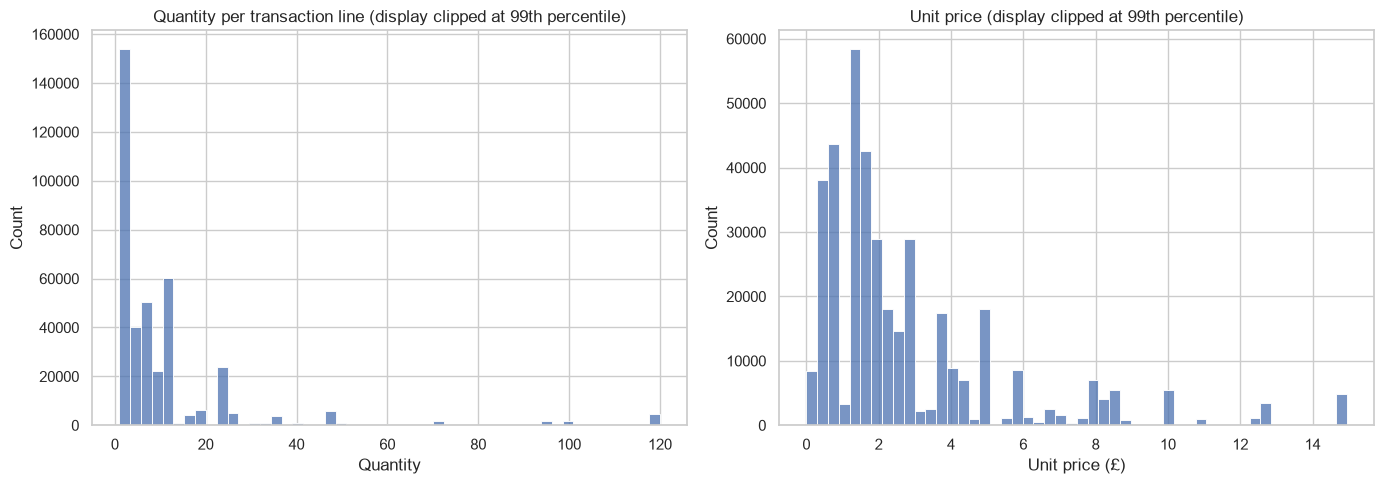

In [7]:
# Plot transaction quantity and unit-price distributions.
# Clip only for visualisation so extreme values do not hide the main distribution.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

quantity_cap = clean_df["Quantity"].quantile(0.99)
price_cap = clean_df["UnitPrice"].quantile(0.99)

sns.histplot(clean_df["Quantity"].clip(upper=quantity_cap), bins=50, ax=axes[0])
axes[0].set_title("Quantity per transaction line (display clipped at 99th percentile)")
axes[0].set_xlabel("Quantity")

sns.histplot(clean_df["UnitPrice"].clip(upper=price_cap), bins=50, ax=axes[1])
axes[1].set_title("Unit price (display clipped at 99th percentile)")
axes[1].set_xlabel("Unit price (£)")

plt.tight_layout()
plt.show()

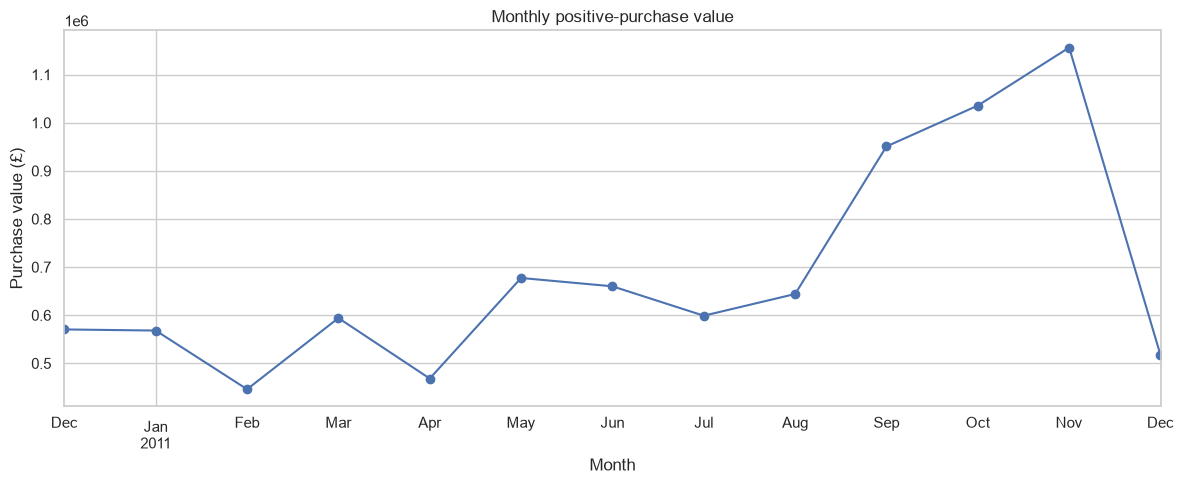

,MonthlySalesGBP
InvoiceDate,
2010-12-01,570422.730
2011-01-01,568101.310
2011-02-01,446084.920
2011-03-01,594081.760
2011-04-01,468374.331
2011-05-01,677355.150
2011-06-01,660046.050
2011-07-01,598962.901
2011-08-01,644051.040


In [8]:
# Summarise monthly positive purchase value.
monthly_sales = (
    clean_df.set_index("InvoiceDate")
    .resample("MS")["LineValue"]
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly positive-purchase value")
plt.xlabel("Month")
plt.ylabel("Purchase value (£)")
plt.tight_layout()
plt.show()

display(monthly_sales.rename("MonthlySalesGBP").to_frame())

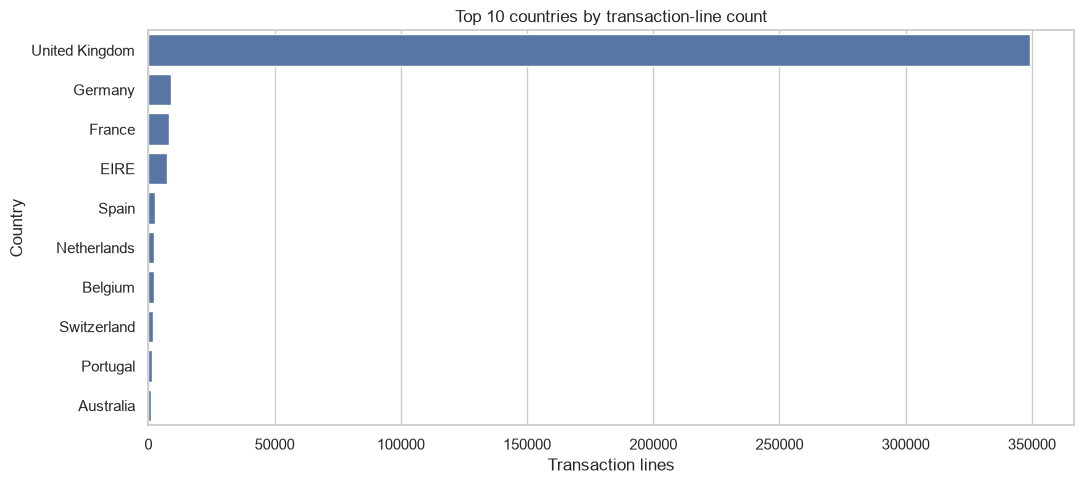

In [9]:
# Display the 10 countries with the most transaction lines.
# Country is used for descriptive EDA only, not as a clustering feature.
top_countries = clean_df["Country"].value_counts().head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 countries by transaction-line count")
plt.xlabel("Transaction lines")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### EDA observations

After running the notebook, add short observations based on the plots: distribution skew, monthly variation, and concentration of transaction activity by country. Do not claim a pattern unless your generated output supports it.

## 5. Engineer customer-level features
Create one row per customer. Recency uses the day after the last transaction in the cleaned dataset as its reference date.

In [10]:
# Use the day after the latest observed transaction as the reference date.
reference_date = clean_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

# Aggregate transaction lines into customer-level purchase features.
customer_features = clean_df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),  # Number of distinct invoices
    Monetary=("LineValue", "sum"),       # Total positive purchase value
    AverageQuantity=("Quantity", "mean"),
    AverageUnitPrice=("UnitPrice", "mean"),
    TotalItems=("Quantity", "sum"),
    Country=("Country", lambda values: (
        values.mode().iloc[0] if not values.mode().empty else "Unknown"
    ))
).reset_index()

# Recency: days between the reference date and each customer's last purchase date.
customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"].dt.normalize()
).dt.days

print("Reference date for Recency:", reference_date.date())
print("Customer-level dataset shape:", customer_features.shape)
display(customer_features.head())

feature_columns = [
    "Recency", "Frequency", "Monetary",
    "AverageQuantity", "AverageUnitPrice"
]
display(customer_features[feature_columns].describe().T)

Reference date for Recency: 2011-12-10
Customer-level dataset shape: (4338, 9)


,CustomerID,LastPurchase,Frequency,Monetary,AverageQuantity,AverageUnitPrice,TotalItems,Country,Recency
0,12346,2011-01-18 10:01:00,1,77183.60,74215.000000,1.040000,74215,United Kingdom,326
1,12347,2011-12-07 15:52:00,7,4310.00,13.505495,2.644011,2458,Iceland,3
2,12348,2011-09-25 13:13:00,4,1797.24,75.516129,5.764839,2341,Finland,76
3,12349,2011-11-21 09:51:00,1,1757.55,8.643836,8.289041,631,Italy,19
4,12350,2011-02-02 16:01:00,1,334.40,11.588235,3.841176,197,Norway,311


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.0000,18.000000,51.000000,142.750000,374.00
Frequency,4338.0,4.272015,7.697998,1.0000,1.000000,2.000000,5.000000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.7500,306.482500,668.570000,1660.597500,280206.02
AverageQuantity,4338.0,45.080599,1203.437983,1.0000,6.042120,10.000000,14.666667,74215.00
AverageUnitPrice,4338.0,4.470820,34.215024,0.1225,2.206415,2.917836,3.832541,2033.10


## 6. Transform and scale the features
The clustering algorithms use numerical behavioural features only. `CustomerID`, `LastPurchase` and `Country` are retained for interpretation but excluded from model input. `log1p` reduces right skew before standardisation.

In [11]:
# Keep only the chosen numerical behavioural features for modelling.
model_df = customer_features.replace([np.inf, -np.inf], np.nan).dropna(
    subset=feature_columns
).copy()

# Check non-negativity before log1p transformation.
if (model_df[feature_columns] < 0).any().any():
    raise ValueError("Negative values found in selected features; review cleaning first.")

# Apply log1p to reduce skew in customer-level features.
X_log = np.log1p(model_df[feature_columns])

# Standardise features so each has comparable scale for distance-based algorithms.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Customers used for clustering:", X_scaled.shape[0])
print("Features used:", feature_columns)

Customers used for clustering: 4338
Features used: ['Recency', 'Frequency', 'Monetary', 'AverageQuantity', 'AverageUnitPrice']


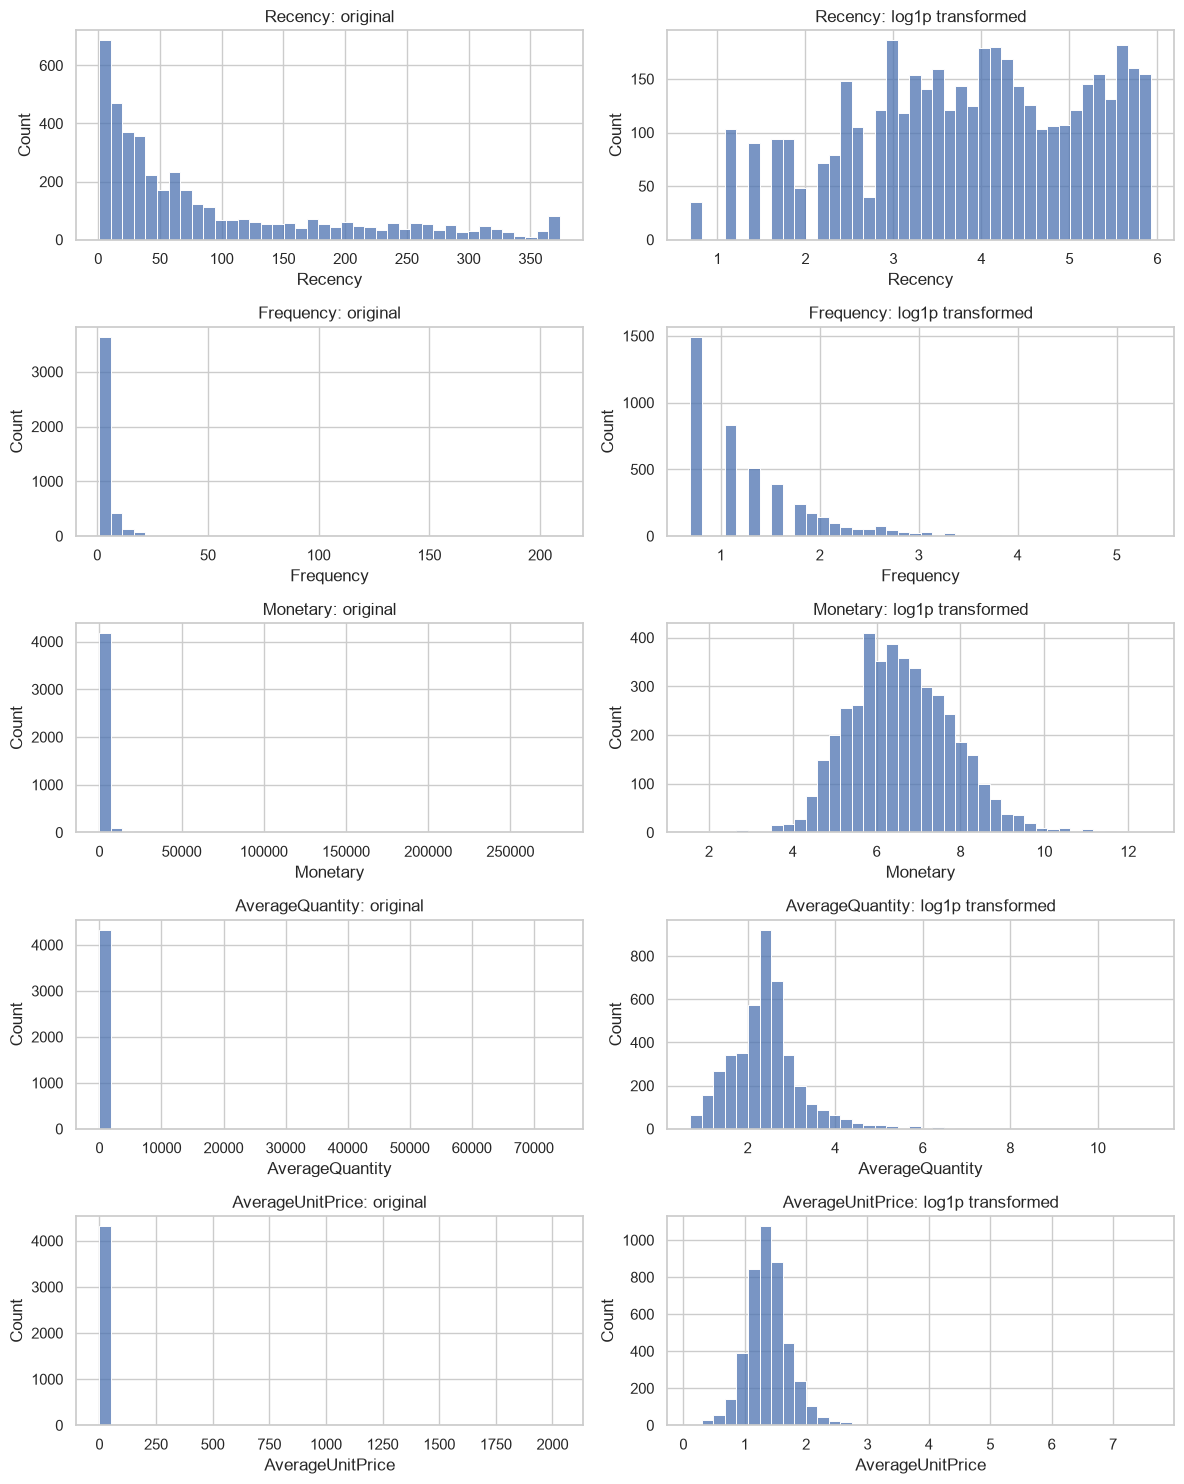

In [12]:
# Compare original and log-transformed feature distributions.
fig, axes = plt.subplots(len(feature_columns), 2, figsize=(12, 3 * len(feature_columns)))

for i, column in enumerate(feature_columns):
    sns.histplot(model_df[column], bins=40, ax=axes[i, 0])
    axes[i, 0].set_title(f"{column}: original")
    sns.histplot(X_log[column], bins=40, ax=axes[i, 1])
    axes[i, 1].set_title(f"{column}: log1p transformed")

plt.tight_layout()
plt.show()

## 7. K-Means clustering and Elbow curve
Try `k` values from 2 to 10. The Elbow curve is mandatory; silhouette scores provide an additional comparison. Review both plots when choosing the final number of clusters.

In [13]:
# Fit K-Means for each candidate k and record inertia and silhouette score.
k_values = range(2, 11)
kmeans_results = []

for k in k_values:
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    candidate_labels = candidate.fit_predict(X_scaled)

    kmeans_results.append({
        "k": k,
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(X_scaled, candidate_labels)
    })

kmeans_tuning = pd.DataFrame(kmeans_results)
display(kmeans_tuning.round(4))

,k,Inertia,Silhouette
0,2,15101.5111,0.3001
1,3,13115.9464,0.2303
2,4,11570.3676,0.2051
3,5,10389.1936,0.2145
4,6,9539.0234,0.1986
5,7,8755.1452,0.1976
6,8,8127.4907,0.1953
7,9,7664.9851,0.1801
8,10,7330.9023,0.1798


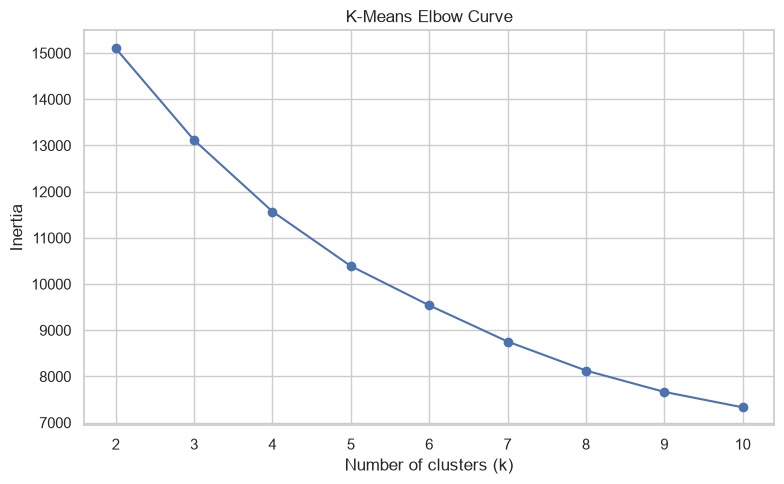

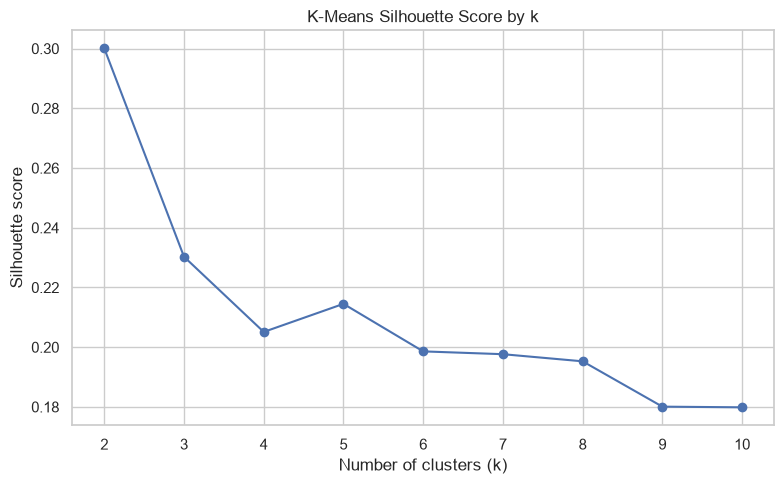

In [14]:
# Elbow curve: inertia generally decreases as the number of clusters increases.
plt.figure(figsize=(8, 5))
plt.plot(kmeans_tuning["k"], kmeans_tuning["Inertia"], marker="o")
plt.title("K-Means Elbow Curve")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Supporting metric: silhouette score (higher is generally better).
plt.figure(figsize=(8, 5))
plt.plot(kmeans_tuning["k"], kmeans_tuning["Silhouette"], marker="o")
plt.title("K-Means Silhouette Score by k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

### Select K-Means cluster count

The next cell selects the candidate with the highest silhouette score as a starting point. Check the Elbow curve as well; if you choose a different `k`, update `selected_k` and explain your reasoning.

In [15]:
# Initial reproducible choice: highest silhouette score among tested k values.
selected_k = int(
    kmeans_tuning.loc[kmeans_tuning["Silhouette"].idxmax(), "k"]
)
print("Initial selected k:", selected_k)

# Fit the final K-Means model with the chosen cluster count.
kmeans_model = KMeans(
    n_clusters=selected_k,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

model_df["KMeansCluster"] = kmeans_labels
print("K-Means cluster sizes:")
display(model_df["KMeansCluster"].value_counts().sort_index())

Initial selected k: 2
K-Means cluster sizes:


KMeansCluster
0    1645
1    2693
Name: count, dtype: int64